In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from matplotlib.patches import FancyArrowPatch
import jax
import jax.numpy as jnp
from jax import jacfwd, jit

In [2]:
m = 1
g = 9.81
dt = 0.05

# Fixed point (hover)
x_fixed = np.array([[0.0], [0.0], [0.0], [0.0], [0.0], [0.0]])
u_fixed = np.array([[m * g], [0.0]]) 

def dynamics(x,u):
    J = 0.05 # Inertia

    # Constants
    k_x = 0.3 # Drag coefficient along body x-axis
    k_y = 0.3 # Drag coefficient along body y-axis
    k_theta = 0.02 # Drag coefficient for theta_dot

    # Extract info from x,u vectors
    theta = x[2, 0]
    x_dot = x[3, 0]
    y_dot = x[4, 0]
    theta_dot = x[5, 0]
    T = u[0, 0]
    tau = u[1, 0]

    # Calculate local velocities (v_x, v_y)
    v_x = x_dot * jnp.cos(theta) + y_dot * jnp.sin(theta)
    v_y = -x_dot * jnp.sin(theta) + y_dot * jnp.cos(theta) 

    # Calculate drag forces
    f_x = -k_x * v_x * jnp.abs(v_x)
    f_y = -k_y * v_y * jnp.abs(v_y)
    f_theta = -k_theta * theta_dot
    
    # Global x-acceleration 
    x_ddot = (1/m) * (-jnp.sin(theta) * (T + f_y) + jnp.cos(theta) * f_x)
    
    # Global y-acceleration 
    y_ddot = (1/m) * (jnp.cos(theta) * (T + f_y) + jnp.sin(theta) * f_x) - g
    
    # Angular acceleration
    theta_ddot = (tau - f_theta) / J

    f = jnp.block([[x_dot], [y_dot], [theta_dot], [x_ddot], [y_ddot], [theta_ddot]])
    return f

In [3]:
def rk4(x, u, dt):
    f1 = dynamics(x, u)
    f2 = dynamics(x + f1 * (dt/2), u)
    f3 = dynamics(x + f2 * (dt/2), u)
    f4 = dynamics(x + f3 * dt, u)
    x_n = x + (dt/6) * (f1 + 2*f2 + 2*f3 + f4)

    return x_n

In [4]:
# Discretize f
def f_discrete(x, u):
    return rk4(x, u, dt)

def linearize(x_fixed, u_fixed):
    
    df_dx = jit(jacfwd(f_discrete, 0)) # diiferentiation over x
    df_du = jit(jacfwd(f_discrete, 1)) # differentiation over u

    A = df_dx(x_fixed, u_fixed)
    B = df_du(x_fixed, u_fixed)

    A = np.array(A).squeeze()
    B = np.array(B).squeeze()

    # Ensure correct shape
    A = A.reshape(6, 6)
    B = B.reshape(6, 2)

    # Constant term c = f(x_fixed, u_fixed) - A*x_fixed - B*u_fixed
    # c accounts for the non-zero operating point in the dynamics
    f_fixed = np.array(f_discrete(x_fixed, u_fixed))
    c = f_fixed - A @ x_fixed - B @ u_fixed

    return A, B, c

In [5]:
def lqr(A, B, Q, Q_N, R):
    N = 6
    M = 2

    K = 200
    # Initialize
    Ps = [np.zeros((N, N))]*K
    Ks = [np.zeros((M, N))]*(K-1)

    # Riccati backward
    Ps[K-1] = Q_N
    for k in range(K-2, -1, -1):
        tmp1 = (R + B.T @ Ps[k+1] @ B)
        tmp2 = B.T @ Ps[k+1] @ A
        Ks[k] = np.linalg.solve(tmp1, tmp2)
        tmp = A - B @ Ks[k]
        Ps[k] = Q + Ks[k].T @ R @ Ks[k] + tmp.T @ Ps[k+1] @ tmp

    # Take the first results
    Kinf = Ks[0]
    Pinf = Ps[0]

    return Pinf, Kinf

In [6]:
# === Linearization and LQR ===
N = 6
M = 2
A, B, c = linearize(x_fixed, u_fixed) 
Q = np.diag([1.0, 1.0, 2000.0, 10.0, 100.0, 2000.0]) # Weights on state error
R = np.diag([0.1, 0.1]) # Weights on control input 
Q_N = Q # Terminal cost
P, Kinf = lqr(np.array(A), np.array(B), Q, Q_N, R)

In [7]:
# =====================================================
# 1. MPC as QP SETUP
# =====================================================

import proxsuite

# MPC Parameters
tc = 0.5 # seconds lookahead
K = round(tc / dt) # Number of steps (horizon)

# Total decision variables: K inputs (u0..uK-1) and K states (x1..xK)
size = K * M + K * N

# ----------------------------
# BUILD COST MATRIX H
# ----------------------------
H = np.zeros((size, size))
offset = 0
for k in range(K):
    # Control u_k
    H[offset:offset + M, offset:offset + M] = R
    offset += M

    # State x_{k+1}
    # Use Q for k=1 to K-1, and Pinf for the terminal state x_K (k=K-1)
    if k == K - 1:
        H[offset:offset + N, offset:offset + N] = P
    else:
        H[offset:offset + N, offset:offset + N] = Q
    offset += N

# -----------------------------------------
# EQUALITY CONSTRAINTS G (Dynamics)
# -----------------------------------------
G = np.zeros((K * N, size))
d = np.zeros(K * N) # d will be updated in the controller

# Dynamic Constraint: x_{k+1} - A*xk - B*uk = c
for k in range(K):
    row_start = k * N
    
    # 1. -B on u_k
    u_idx = k * (M + N) 
    G[row_start:row_start + N, u_idx:u_idx + M] = -B 
    
    # 2. I on x_{k+1}
    x_plus_1_idx = k * (M + N) + M
    G[row_start:row_start + N, x_plus_1_idx:x_plus_1_idx + N] = np.eye(N)
    
    # 3. -A on x_k (Skip k=0, since x0 is the initial condition)
    if k > 0:
        x_idx = (k - 1) * (M + N) + M
        G[row_start:row_start + N, x_idx:x_idx + N] = -A 

# -----------------------------------
# INEQUALITY CONSTRAINTS C (Control Limits)
# -----------------------------------
C = np.zeros((K * M, size))
lb = np.zeros(K * M)
ub = np.zeros(K * M)

# Actuator limits 
u_min_abs = np.array([0.5 * m * g, -0.5]) # [T_min, tau_min]
u_max_abs = np.array([1.5 * m * g, 0.5]) # [T_max, tau_max]

for k in range(K):
    u_idx = k * (M + N)
    row_start = k * M
    
    C[row_start:row_start + M, u_idx:u_idx + M] = np.eye(M)
    lb[row_start:row_start + M] = u_min_abs
    ub[row_start:row_start + M] = u_max_abs

# ----------------------------
# Initialization for proxsuite
# ----------------------------
H = np.array(H, dtype=np.float64)
h = np.zeros(size, dtype=np.float64) 
G = np.array(G, dtype=np.float64)
d = np.array(d, dtype=np.float64)
C = np.array(C, dtype=np.float64)
lb = np.array(lb, dtype=np.float64)
ub = np.array(ub, dtype=np.float64)

qp_dim = H.shape[0]
qp_dim_eq = G.shape[0]
qp_dim_in = C.shape[0]

# Initialize QP
qp = proxsuite.proxqp.dense.QP(qp_dim, qp_dim_eq, qp_dim_in)
qp.init(H, h, G, d, C, lb, ub)

prev_sol_x = np.zeros(qp_dim)
prev_sol_eq = np.zeros(qp_dim_eq)
prev_sol_ineq = np.zeros(qp_dim_in)

In [8]:
# =====================================================
# 2. MPC CONTROLLER 
# =====================================================

def mpc_controller(x_current, x_ref):
    """
    Computes the optimal control input u_0 using MPC.
    x_current: Current state vector (N x 1)
    x_ref: Desired state vector (N x 1)
    """
    global prev_sol_x, prev_sol_eq, prev_sol_ineq

    # -------------------------
    # Update d 
    # -------------------------
    d = np.zeros(K * N)
    d[0:N] = (A @ x_current + c).reshape(-1)  # k=0
    for k in range(1, K):
        d[k*N:(k+1)*N] = c.reshape(-1)

    # -------------------------
    # Update h (Linear Cost Term)
    # -------------------------
    h = np.zeros(size)

    offset = 0
    for k in range(K):
        # control u_k 
        h[offset:offset+M] = - (R @ u_fixed).reshape(-1)
        offset += M

        # state x_{k+1}
        if k == K-1:
            # Terminal step uses LQR terminal cost P
            h[offset:offset+N] = - (P @ x_ref).reshape(-1)
        else:
            h[offset:offset+N] = - (Q @ x_ref).reshape(-1)
        offset += N

    # -------------------------
    # Solve QP 
    # -------------------------
    qp.update(H=H, g=h, A=G, b=d, C=C, l=lb, u=ub)
    qp.solve(prev_sol_x, prev_sol_eq, prev_sol_ineq)

    prev_sol_x = qp.results.x.copy()
    prev_sol_eq = qp.results.y.copy()
    prev_sol_ineq = qp.results.z.copy()

    # -------------------------
    # Extract first control input u_0
    # -------------------------
    u_0 = qp.results.x[:M].reshape((M, 1))
    print(u_0)
    return u_0



--- Starting MPC Simulation ---
[[ 4.905     ]
 [-0.50000356]]
[[ 4.905    ]
 [-0.4999956]]
[[ 4.905     ]
 [-0.49996232]]
[[ 4.905     ]
 [-0.49995974]]
[[4.90505013]
 [0.19675635]]
[[4.90501984]
 [0.18225096]]
[[4.90500615]
 [0.16667211]]
[[4.90500227]
 [0.15308593]]
[[4.90500144]
 [0.14133315]]
[[4.90500089]
 [0.13118615]]
[[4.90500047]
 [0.12237084]]
[[4.90500047]
 [0.1146093 ]]
[[5.67118495]
 [0.10764942]]
[[6.69185537]
 [0.09746631]]
[[7.07612633]
 [0.08706488]]
[[7.09636415]
 [0.08070996]]
[[6.95932993]
 [0.0764438 ]]
[[6.79420566]
 [0.07291876]]
[[6.66498674]
 [0.06939828]]
[[6.59279408]
 [0.06560797]]
[[6.57446035]
 [0.06152774]]
[[6.59659131]
 [0.05726002]]
[[6.6442719 ]
 [0.05294115]]
[[6.70512703]
 [0.04869474]]
[[6.77046228]
 [0.04461114]]
[[6.83490917]
 [0.04074982]]
[[6.89558696]
 [0.03714126]]
[[6.95123096]
 [0.03379794]]
[[7.00158858]
 [0.03071912]]
[[7.04680754]
 [0.02789492]]
[[7.08765445]
 [0.02531531]]
[[7.12451204]
 [0.02296132]]
[[7.157984  ]
 [0.02081831]]
[[7.

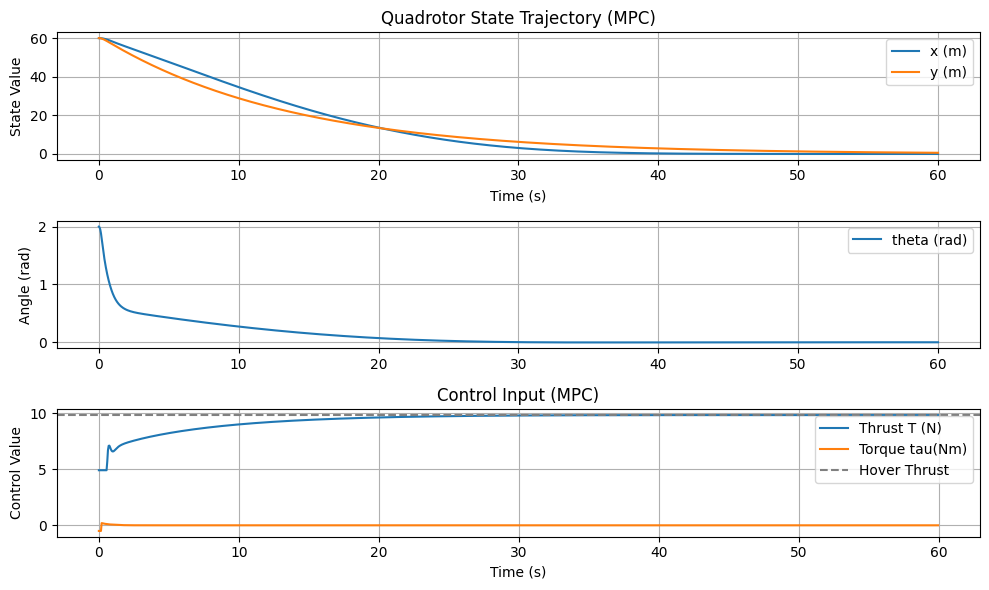

In [13]:
# =====================================================
# 3. SIMULATION 
# =====================================================

x_0 = np.array([[60.0], [60.0], [2.0], [0.0], [0.0], [0.0]]) # Initial state 
x_ref = np.array([[0.0], [0.0], [0.0], [0.0], [0.0], [0.0]]) # Target 

T_sim = 60.0 # Total simulation time
N_sim = int(T_sim / dt)

X_hist = [x_0]
U_hist = []
x_k = x_0

# Input constraints
T_min, T_max = 0.5*m*g, 1.5*m*g
tau_min, tau_max = -0.5, 0.5
   
print("\n--- Starting MPC Simulation ---")

for _ in range(N_sim):
    # Compute optimal control
    u_k = mpc_controller(x_k, x_ref)
    # Clip control signals
    u_k[0, 0] = np.clip(u_k[0, 0], T_min, T_max)
    u_k[1, 0] = np.clip(u_k[1, 0], tau_min, tau_max)
    U_hist.append(u_k.copy())
    
    # Integrate nonlinear dynamics
    x_k = rk4(x_k, u_k, dt)
    X_hist.append(x_k)
    
X_hist = np.hstack(X_hist)
U_hist = np.hstack(U_hist)

# --- Plotting Results ---
time_vec = np.linspace(0, T_sim, N_sim + 1)

plt.figure(figsize=(10, 6))

# State Plots
plt.subplot(3, 1, 1)
plt.plot(time_vec, X_hist[0, :], label='x (m)')
plt.plot(time_vec, X_hist[1, :], label='y (m)')
plt.title('Quadrotor State Trajectory (MPC)')
plt.xlabel('Time (s)')
plt.ylabel('State Value')
plt.legend()
plt.grid(True)

plt.subplot(3, 1, 2)
plt.plot(time_vec, X_hist[2, :], label='theta (rad)')
plt.ylabel('Angle (rad)')
plt.legend()
plt.grid(True)

# Control Plots
plt.subplot(3, 1, 3)
plt.plot(time_vec[:-1], U_hist[0, :], label='Thrust T (N)')
plt.plot(time_vec[:-1], U_hist[1, :], label='Torque tau(Nm)') 
plt.axhline(u_fixed[0,0], color='gray', linestyle='--', label='Hover Thrust')
plt.title('Control Input (MPC)')
plt.xlabel('Time (s)')
plt.ylabel('Control Value')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [ ]:
%matplotlib inline
from IPython.display import HTML, display

# =====================================================
# 3. ANIMATION 
# =====================================================

fig, ax = plt.subplots(figsize=(6, 4))
ax.set_xlim(-40, 40)
ax.set_ylim(-40, 40)
ax.set_aspect('equal')
ax.set_title("Quadrotor Stabilization with MPC")
ax.set_xlabel("x (m)")
ax.set_ylabel("y (m)")

# Quadrotor body
body, = ax.plot([], [], 'k-', lw=4)
center, = ax.plot([], [], 'ro', markersize=12)
time_text = ax.text(0.02, 0.95, '', fontsize=10)

L = 60.0  # arm length

def init():
    body.set_data([], [])
    center.set_data([], [])
    time_text.set_text('')
    return body, center, time_text

def update(frame):
    x_pos = X_hist[0, frame]
    y_pos = X_hist[1, frame]
    theta = X_hist[2, frame]

    # Compute rotor arm endpoints
    x1 = x_pos - (L/2) * np.cos(theta)
    x2 = x_pos + (L/2) * np.cos(theta)
    y1 = y_pos - (L/2) * np.sin(theta)
    y2 = y_pos + (L/2) * np.sin(theta)

    body.set_data([x1, x2], [y1, y2])
    center.set_data([x_pos], [y_pos])

    time_text.set_text(f"t = {frame*dt:.2f} s")

    return body, center, time_text
anim = FuncAnimation(fig, update, frames=X_hist.shape[1], init_func=init, blit=False, interval=100)
# Save as GIF
anim.save('animation.gif', writer='pillow', fps=10)

# Display in Notebook
from IPython.display import Image
Image(filename='animation.gif')



--- Starting MPC Simulation ---
[[4.90499797]
 [0.21866581]]
[[4.90506473]
 [0.07494733]]
[[ 4.90501446]
 [-0.23289148]]
[[4.90503885]
 [0.11959529]]
[[4.90501719]
 [0.10302046]]
[[ 4.9050968 ]
 [-0.15094478]]
[[ 4.90506596]
 [-0.20776205]]
[[ 4.90504114e+00]
 [-4.93828963e-04]]
[[4.90504499]
 [0.17282264]]
[[4.90507386]
 [0.05235776]]
[[ 4.9050004 ]
 [-0.26510594]]
[[ 4.90504467]
 [-0.10665165]]
[[4.90503776]
 [0.04159713]]
[[4.9050503 ]
 [0.21310831]]
[[4.90500514]
 [0.20281202]]
[[ 4.905     ]
 [-0.50000238]]
[[4.90508377]
 [0.25773146]]
[[ 4.90499571]
 [-0.05877942]]
[[ 4.90502643]
 [-0.18585973]]
[[4.9050426 ]
 [0.15987685]]
[[4.905005  ]
 [0.19109037]]
[[ 4.90501958]
 [-0.10656189]]
[[ 4.90501104]
 [-0.0780515 ]]
[[4.90501701]
 [0.0148855 ]]
[[ 4.90501679]
 [-0.01521285]]
[[4.90504625]
 [0.07077253]]
[[ 4.90502825]
 [-0.07527373]]
[[4.90500265]
 [0.20020903]]
[[ 4.90500011]
 [-0.18767254]]
[[4.90499948]
 [0.02205035]]
[[ 4.90501592]
 [-0.08921949]]
[[4.90500578]
 [0.17767419]]
[

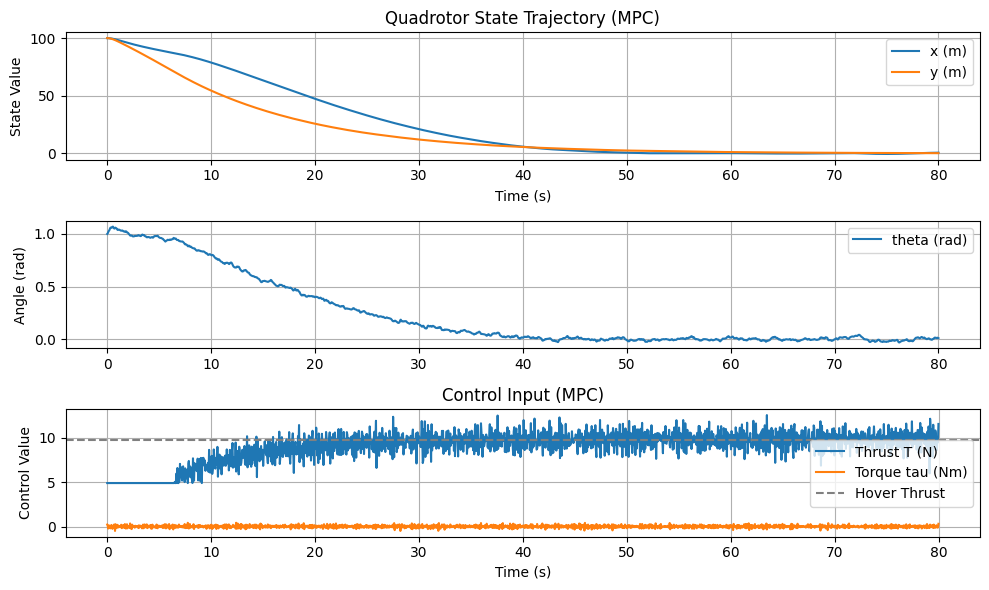

In [11]:
# =====================================================
# 4. SIMULATION WITH NOISE
# =====================================================

x_0 = np.array([[100.0], [100.0], [1.0], [0.0], [0.0], [0.0]]) # Initial state
x_ref = np.array([[0.0], [0.0], [0.0], [0.0], [0.0], [0.0]]) # Target 

T_sim = 80.0 # Total simulation time
N_sim = int(T_sim / dt)

X_hist = [x_0]
U_hist = []
x_k = x_0

# Define standard deviations (sigma) for each state component
sigma_diag = np.array([0.1, 0.1, 0.05, 0.05, 0.05, 0.05]) 

# Diagonal Covariance Matrix
Sigma = np.diag(sigma_diag**2)

print("\n--- Starting MPC Simulation ---")

for _ in range(N_sim):
    # Add noise to the true state x_k to get the observed state y_k
    noise = np.random.multivariate_normal(np.zeros(N), Sigma).reshape(N, 1)
    y_k = x_k + noise 

    # Compute optimal control using the noisy observation
    u_k = mpc_controller(y_k, x_ref)
    U_hist.append(u_k.copy())

    # Integrate the true state (x_k) using the computed control u_k
    x_k = np.array(f_discrete(x_k, u_k))
    X_hist.append(x_k)
    
X_hist = np.hstack(X_hist)
U_hist = np.hstack(U_hist)

# --- Plotting Results ---
time_vec = np.linspace(0, T_sim, N_sim + 1)

plt.figure(figsize=(10, 6))

# State Plots
plt.subplot(3, 1, 1)
plt.plot(time_vec, X_hist[0, :], label='x (m)')
plt.plot(time_vec, X_hist[1, :], label='y (m)')
plt.title('Quadrotor State Trajectory (MPC)')
plt.xlabel('Time (s)')
plt.ylabel('State Value')
plt.legend()
plt.grid(True)

plt.subplot(3, 1, 2)
plt.plot(time_vec, X_hist[2, :], label='theta (rad)')
plt.ylabel('Angle (rad)')
plt.legend()
plt.grid(True)

# Control Plots
plt.subplot(3, 1, 3)
plt.plot(time_vec[:-1], U_hist[0, :], label='Thrust T (N)')
plt.plot(time_vec[:-1], U_hist[1, :], label='Torque tau (Nm)')
plt.axhline(u_fixed[0,0], color='gray', linestyle='--', label='Hover Thrust')
plt.title('Control Input (MPC)')
plt.xlabel('Time (s)')
plt.ylabel('Control Value')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()